In [1]:
# STEP 1: Imports and settings

#Hide extra messages/warnings so the output stays clean
import os, warnings, logging
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     
warnings.filterwarnings("ignore")            
logging.getLogger().setLevel(logging.ERROR)  

#Basic libraries
import numpy as np                
import pandas as pd               
import matplotlib.pyplot as plt  

#ensorFlow
# AIF360's Adversarial Debiasing is written in the old TensorFlow 1,
# so we load the "old" version of the API (compat.v1)
import tensorflow.compat.v1 as tf
tf.disable_eager_execution()    

#ompatibility fix
# pandas 3 stores text in a new way that AIF360 does not understand.
# If we have pandas 3, we switch back to the old way.
if int(pd.__version__.split(".")[0]) >= 3:
    pd.set_option("future.infer_string", False)

#Tools from scikit-learn
from sklearn.model_selection import train_test_split   
from sklearn.preprocessing import StandardScaler      

#Tools from AIF360 
from aif360.datasets import StandardDataset            
from aif360.metrics import BinaryLabelDatasetMetric   
from aif360.metrics import ClassificationMetric        
from aif360.algorithms.inprocessing import AdversarialDebiasing   

#Fixed random seed
SEED = 42
np.random.seed(SEED)

# If this line is printed, everything loaded correctly
print("OK, tf:", tf.__version__, "| pandas:", pd.__version__)


OK, tf: 2.22.0-rc0 | pandas: 3.1.1


In [2]:
# STEP 2: Load the three datasets

# Links to the raw data files (public copies of the UCI / ProPublica data on GitHub)
URLS = {
    "adult":  "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv",
    "german": "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv",
    "compas": "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv",
}

# Create a "data" folder to keep the downloaded files
os.makedirs("data", exist_ok=True)

def get(name):
    """Download a file once and return its local path."""
    path = os.path.join("data", os.path.basename(URLS[name]))
    if not os.path.exists(path):           
        import urllib.request
        urllib.request.urlretrieve(URLS[name], path)
    return path


# ADULT: predict if a person earns more than 50K per year
# Protected attribute: sex (Male = privileged group)
def load_adult():
    # The file has no header, so we give the column names ourselves
    cols = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
            "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
            "hours-per-week", "native-country", "income"]
    # "?" means missing value -> we remove those rows with dropna()
    df = pd.read_csv(get("adult"), names=cols, na_values="?", skipinitialspace=True).dropna()

    # Turn the label into numbers: 1 if income > 50K, else 0
    df["income"] = df["income"].str.contains(">50K").astype(int)

    # StandardDataset turns the DataFrame into an AIF360 dataset:
    # - label_name: the column we want to predict
    # - favorable_classes: which label value is the "good" outcome
    # - protected_attribute_names / privileged_classes: the sensitive attribute and the privileged group
    # - categorical_features: text columns that will be one-hot encoded
    # - features_to_drop: columns we don't use (fnlwgt is a census sampling weight, not a real feature)
    ds = StandardDataset(
        df, label_name="income", favorable_classes=[1],
        protected_attribute_names=["sex"], privileged_classes=[["Male"]],
        categorical_features=["workclass", "education", "marital-status", "occupation",
                              "relationship", "race", "native-country"],
        features_to_drop=["fnlwgt"])
    return ds, "sex"


# GERMAN CREDIT: predict if a person is a good credit risk
# Protected attribute: age (older than 25)
def load_german():

    cols = ["status", "month", "credit_history", "purpose", "credit_amount", "savings",
            "employment", "investment_as_income_percentage", "personal_status", "other_debtors",
            "residence_since", "property", "age", "installment_plans", "housing",
            "number_of_credits", "skill_level", "people_liable_for", "telephone",
            "foreign_worker", "credit"]
    df = pd.read_csv(get("german"), names=cols)

    
    df["sex"] = df["personal_status"].map(
        {"A91": "male", "A93": "male", "A94": "male", "A92": "female", "A95": "female"})


    df["credit"] = (df["credit"] == 1).astype(int)

    ds = StandardDataset(
        df, label_name="credit", favorable_classes=[1],
        protected_attribute_names=["age"],
        privileged_classes=[lambda x: x > 25],    
        categorical_features=["status", "credit_history", "purpose", "savings", "employment",
                              "other_debtors", "property", "installment_plans", "housing",
                              "skill_level", "telephone", "foreign_worker", "sex"],
        features_to_drop=["personal_status"])
    return ds, "age"


# COMPAS: predict if a person will NOT re-offend within 2 years
# Protected attribute: race (Caucasian = privileged group)
def load_compas():
    df = pd.read_csv(get("compas"))

    # Same data cleaning as ProPublica's original analysis:
    # keep only rows where the data is reliable
    df = df[(df.days_b_screening_arrest <= 30) & (df.days_b_screening_arrest >= -30)
            & (df.is_recid != -1) & (df.c_charge_degree != "O") & (df.score_text != "N/A")]

    # Keep only the columns we need
    df = df[["sex", "age", "age_cat", "race", "juv_fel_count", "juv_misd_count",
             "juv_other_count", "priors_count", "c_charge_degree", "two_year_recid"]].copy()

    # The good outcome is NOT re-offending, so we flip the label: 1 = no re-offense
    df["no_recid"] = 1 - df.pop("two_year_recid")

    ds = StandardDataset(
        df, label_name="no_recid", favorable_classes=[1],
        protected_attribute_names=["race"], privileged_classes=[["Caucasian"]],
        categorical_features=["sex", "age_cat", "c_charge_degree"])
    return ds, "race"


# Load all three and print a short overview
DATASETS = {"Adult": load_adult, "German": load_german, "COMPAS": load_compas}

data = {} 
for name, loader in DATASETS.items():
    ds, prot = loader()
    data[name] = (ds, prot)
    print(f"{name:7s} | rows = {ds.features.shape[0]:6d} | features = {ds.features.shape[1]:3d} | "
          f"protected = '{prot}' | share with favorable label = {ds.labels.mean():.3f}")

Adult   | rows =  45222 | features = 102 | protected = 'sex' | share with favorable label = 0.248
German  | rows =   1000 | features =  59 | protected = 'age' | share with favorable label = 0.700
COMPAS  | rows =   6172 | features =  13 | protected = 'race' | share with favorable label = 0.545


In [3]:
# STEP 3: Fairness of the ORIGINAL labels (before any training)

def get_groups(prot):
    """Return the unprivileged and privileged groups in the format AIF360 expects.
    After loading, the protected attribute is 1 for the privileged group and 0 otherwise."""
    unprivileged = [{prot: 0}]
    privileged = [{prot: 1}]
    return unprivileged, privileged


def scaled_copy(ds, scaler):
    """Return a copy of the dataset with standardized features (mean 0, std 1).
    This matters for consistency: it uses distances between people (kNN),
    and without scaling, big-number features like 'capital-gain' would dominate."""
    out = ds.copy(deepcopy=True)
    out.features = scaler.transform(ds.features)
    return out


def fairness_metrics(ds, prot):
    """Compute DP_Diff, DIR and consistency from the labels stored in the dataset.
    (Here these are the true labels; later we will pass in the predicted labels.)"""
    unpriv, priv = get_groups(prot)
    m = BinaryLabelDatasetMetric(ds, unprivileged_groups=unpriv, privileged_groups=priv)
    return {
        "DP_Diff": m.statistical_parity_difference(),   
        "DIR": m.disparate_impact(),                    
        "Consistency": float(np.ravel(m.consistency(n_neighbors=5))[0]),  
    }


# Compute the metrics for each dataset
before_rows = []
for name, (ds, prot) in data.items():
    scaler = StandardScaler().fit(ds.features)
    ds_scaled = scaled_copy(ds, scaler)          
    before_rows.append({"Dataset": name, **fairness_metrics(ds_scaled, prot)})

before = pd.DataFrame(before_rows).set_index("Dataset")
before.round(4)

,DP_Diff,DIR,Consistency
Dataset,,,
Adult,-0.1989,0.3635,0.8285
German,-0.1494,0.7948,0.7400
COMPAS,-0.0975,0.8400,0.6583


In [4]:
# STEP 4: Stratified train/test split + feature scaling

TEST_SIZE = 0.3  

def stratified_split(ds, prot, test_size=TEST_SIZE, seed=SEED):
    """Split the dataset so that train and test keep the same mix of
    labels AND protected groups."""
    y = ds.labels.ravel().astype(int)                     
    col = ds.protected_attribute_names.index(prot)        
    a = ds.protected_attributes[:, col].astype(int)       

    # Combine label and group into one "stratum" with 4 possible values:
    # 0 = (label 0, unpriv), 1 = (label 0, priv), 2 = (label 1, unpriv), 3 = (label 1, priv)
    strata = y * 2 + a

    # Split the row indices, keeping the same share of each stratum in train and test
    idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=test_size,
                                           stratify=strata, random_state=seed)
    return ds.subset(idx_train), ds.subset(idx_test)


splits = {}       
check_rows = [] 

for name, (ds, prot) in data.items():
    train, test = stratified_split(ds, prot)

    # Fit the scaler on the TRAIN set only (to avoid data leakage),
    # then apply the same scaling to both train and test
    scaler = StandardScaler().fit(train.features)
    train_s = scaled_copy(train, scaler)
    test_s = scaled_copy(test, scaler)
    splits[name] = (train_s, test_s, prot)

    # Save some numbers to check that train and test look alike
    for part, d in [("train", train), ("test", test)]:
        col = d.protected_attribute_names.index(prot)
        check_rows.append({"Dataset": name, "Split": part,
                           "Rows": len(d.labels),
                           "Favorable rate": d.labels.mean(),
                           "Privileged share": d.protected_attributes[:, col].mean()})

check = pd.DataFrame(check_rows).set_index(["Dataset", "Split"])
check.round(4)

Rows  Favorable rate  Privileged share
Dataset Split                                         
Adult   train  31655          0.2478            0.6751
        test   13567          0.2479            0.6750
German  train    700          0.7000            0.8100
        test     300          0.7000            0.8100
COMPAS  train   4320          0.5449            0.3407
        test    1852          0.5448            0.3407

In [5]:
# STEP 5: Train the models (in-processing mitigation)

import time

def train_and_predict(train, test, prot, debias, scope_name, epochs=50, adv_weight=0.1):
    """Train an AdversarialDebiasing model on 'train' and return its predictions on 'test'.
    debias=False -> plain neural network (baseline, no adversary)
    debias=True  -> predictor + adversary (the method from the paper)"""
    unpriv, priv = get_groups(prot)

    # Start from a clean TensorFlow graph and fixed seeds, so every run is reproducible
    tf.reset_default_graph()
    np.random.seed(SEED)
    tf.set_random_seed(SEED)
    sess = tf.Session()

    model = AdversarialDebiasing(
        unprivileged_groups=unpriv,
        privileged_groups=priv,
        scope_name=scope_name,              
        debias=debias,                     
        sess=sess,
        seed=SEED,
        num_epochs=epochs,                  
        batch_size=128,
        adversary_loss_weight=adv_weight,   
        classifier_num_hidden_units=200)    

    model.fit(train)              
    pred = model.predict(test)    
    sess.close()
    return pred


predictions = {}   

for name, (train_s, test_s, prot) in splits.items():
    start = time.time()

    # 1) Baseline: same network, but WITHOUT the adversary
    pred_base = train_and_predict(train_s, test_s, prot, debias=False,
                                  scope_name=f"{name}_baseline")

    # 2) Adversarial debiasing: WITH the adversary
    pred_adv = train_and_predict(train_s, test_s, prot, debias=True,
                                 scope_name=f"{name}_debiased")

    predictions[name] = {"Baseline NN": pred_base, "Adversarial debiasing": pred_adv}
    print(f"{name}: done in {time.time() - start:.0f} seconds")

Instructions for updating:
Please use `rate` instead of `keep_prob`. Rate should be set to `rate = 1 - keep_prob`.


Instructions for updating:
Please use `rate` instead of `keep_prob`. Rate should be set to `rate = 1 - keep_prob`.


epoch 0; iter: 0; batch classifier loss: 0.963571
epoch 0; iter: 200; batch classifier loss: 0.413257
epoch 1; iter: 0; batch classifier loss: 0.262275
epoch 1; iter: 200; batch classifier loss: 0.347010
epoch 2; iter: 0; batch classifier loss: 0.289427
epoch 2; iter: 200; batch classifier loss: 0.266461
epoch 3; iter: 0; batch classifier loss: 0.299680
epoch 3; iter: 200; batch classifier loss: 0.295112
epoch 4; iter: 0; batch classifier loss: 0.298592
epoch 4; iter: 200; batch classifier loss: 0.288564
epoch 5; iter: 0; batch classifier loss: 0.270530
epoch 5; iter: 200; batch classifier loss: 0.320105
epoch 6; iter: 0; batch classifier loss: 0.326419
epoch 6; iter: 200; batch classifier loss: 0.261135
epoch 7; iter: 0; batch classifier loss: 0.290340
epoch 7; iter: 200; batch classifier loss: 0.221263
epoch 8; iter: 0; batch classifier loss: 0.269802
epoch 8; iter: 200; batch classifier loss: 0.275802
epoch 9; iter: 0; batch classifier loss: 0.369100
epoch 9; iter: 200; batch classi

In [6]:
# STEP 6: Metrics on the held-out TEST set

def performance_metrics(ds_true, ds_pred, prot):
    """Compare predictions with the true labels: accuracy, balanced accuracy,
    and average odds difference (the fairness goal the adversary actually targets)."""
    unpriv, priv = get_groups(prot)
    cm = ClassificationMetric(ds_true, ds_pred, unprivileged_groups=unpriv, privileged_groups=priv)
    return {
        "Accuracy": cm.accuracy(),                                     
        "Balanced accuracy": 0.5 * (cm.true_positive_rate()            
                                    + cm.true_negative_rate()),        
        "Avg. odds diff.": cm.average_odds_difference(),               
    }


after_rows = []
for name, (train_s, test_s, prot) in splits.items():
    # Reference row: fairness of the TRUE labels of the test set (same people as the predictions)
    after_rows.append({"Dataset": name, "Model": "Original labels (test)",
                       **fairness_metrics(test_s, prot)})

    # One row per model: fairness of the PREDICTED labels + predictive performance
    for model_name, pred in predictions[name].items():
        after_rows.append({"Dataset": name, "Model": model_name,
                           **fairness_metrics(pred, prot),
                           **performance_metrics(test_s, pred, prot)})

after = pd.DataFrame(after_rows).set_index(["Dataset", "Model"])
after.round(4)

DP_Diff     DIR  Consistency  Accuracy  \
Dataset Model                                                            
Adult   Original labels (test)  -0.1989  0.3636       0.8240       NaN   
        Baseline NN             -0.1898  0.3326       0.9375    0.8468   
        Adversarial debiasing   -0.1013  0.5675       0.9416    0.8437   
German  Original labels (test)  -0.1494  0.7948       0.7533       NaN   
        Baseline NN             -0.0615  0.9230       0.8287    0.8000   
        Adversarial debiasing    0.1466  1.2108       0.8027    0.7900   
COMPAS  Original labels (test)  -0.0967  0.8411       0.6614       NaN   
        Baseline NN             -0.1979  0.7326       0.9578    0.6836   
        Adversarial debiasing   -0.0645  0.8989       0.9610    0.6712   

                                Balanced accuracy  Avg. odds diff.  
Dataset Model                                                       
Adult   Original labels (test)                NaN              NaN  
        Baseline NN                        0.7776          -0.0786  
        Adversarial debiasing              0.7590           0.0599  
German  Original labels (test)                NaN              NaN  
        Baseline NN                        0.7206           0.0301  
        Adversarial debiasing              0.7389           0.2609  
COMPAS  Original labels (test)                NaN              NaN  
        Baseline NN                        0.6752          -0.1774  
        Adversarial debiasing              0.6639          -0.0408

Ideal  Before (original labels)  Baseline NN  \
Dataset Metric                                                      
Adult   DP_Diff        0.0                   -0.1989      -0.1898   
        DIR            1.0                    0.3636       0.3326   
        Consistency    1.0                    0.8240       0.9375   
German  DP_Diff        0.0                   -0.1494      -0.0615   
        DIR            1.0                    0.7948       0.9230   
        Consistency    1.0                    0.7533       0.8287   
COMPAS  DP_Diff        0.0                   -0.0967      -0.1979   
        DIR            1.0                    0.8411       0.7326   
        Consistency    1.0                    0.6614       0.9578   

                     After (adv. debiasing)  Distance to ideal: before  \
Dataset Metric                                                           
Adult   DP_Diff                     -0.1013                     0.1989   
        DIR                          0.5675                     0.6364   
        Consistency                  0.9416                     0.1760   
German  DP_Diff                      0.1466                     0.1494   
        DIR                          1.2108                     0.2052   
        Consistency                  0.8027                     0.2467   
COMPAS  DP_Diff                     -0.0645                     0.0967   
        DIR                          0.8989                     0.1589   
        Consistency                  0.9610                     0.3386   

                     Distance to ideal: after Improved?  
Dataset Metric                                           
Adult   DP_Diff                        0.1013       yes  
        DIR                            0.4325       yes  
        Consistency                    0.0584       yes  
German  DP_Diff                        0.1466       yes  
        DIR                            0.2108        no  
        Consistency                    0.1973       yes  
COMPAS  DP_Diff                        0.0645       yes  
        DIR                            0.1011       yes  
        Consistency                    0.0390       yes

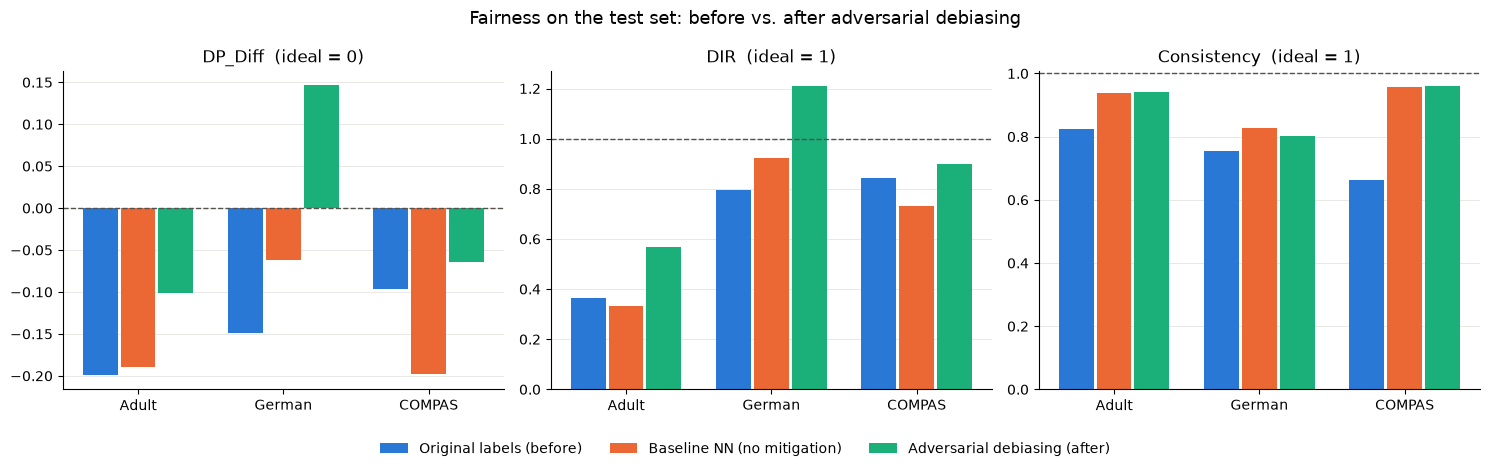

In [7]:
# STEP 7: Compare fairness BEFORE vs AFTER mitigation

#7a. Comparison table
# "Before" = true labels of the test set, "After" = predictions of the debiased model.
# For each metric we also show how far it is from its ideal value.
comparison_rows = []
for name in after.index.get_level_values("Dataset").unique():
    before_row = after.loc[(name, "Original labels (test)")]
    base_row = after.loc[(name, "Baseline NN")]
    after_row = after.loc[(name, "Adversarial debiasing")]

    for metric, ideal in [("DP_Diff", 0.0), ("DIR", 1.0), ("Consistency", 1.0)]:
        gap_before = abs(before_row[metric] - ideal)   # distance from the ideal value before
        gap_after = abs(after_row[metric] - ideal)     # distance from the ideal value after
        comparison_rows.append({
            "Dataset": name, "Metric": metric, "Ideal": ideal,
            "Before (original labels)": before_row[metric],
            "Baseline NN": base_row[metric],
            "After (adv. debiasing)": after_row[metric],
            "Distance to ideal: before": gap_before,
            "Distance to ideal: after": gap_after,
            "Improved?": "yes" if gap_after < gap_before else "no",
        })

comparison = pd.DataFrame(comparison_rows).set_index(["Dataset", "Metric"])
display(comparison.round(4))


#7b. Bar chart
# One panel per metric (they have different scales, so they get separate axes).
# The dashed line marks the ideal value.
series = [("Original labels (test)", "Original labels (before)",      "#2a78d6"),   # blue
          ("Baseline NN",            "Baseline NN (no mitigation)",   "#eb6834"),   # orange
          ("Adversarial debiasing",  "Adversarial debiasing (after)", "#1baf7a")]   # green
metrics = [("DP_Diff", 0.0), ("DIR", 1.0), ("Consistency", 1.0)]
names = list(after.index.get_level_values("Dataset").unique())
x = np.arange(len(names))   
width = 0.26                

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (metric, ideal) in zip(axes, metrics):
    for k, (row_name, label, color) in enumerate(series):
        values = [after.loc[(n, row_name), metric] for n in names]
        ax.bar(x + (k - 1) * width, values, width - 0.02, color=color, label=label)
    ax.axhline(ideal, color="#52514e", linewidth=1, linestyle="--")   
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_title(f"{metric}  (ideal = {ideal:g})")
    ax.spines[["top", "right"]].set_visible(False)                   
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.6)
    ax.set_axisbelow(True)

# One shared legend under the three panels
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Fairness on the test set: before vs. after adversarial debiasing", fontsize=13)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig("fairness_comparison.png", dpi=150, bbox_inches="tight")
plt.show()